# Data Mining — Linear Regression — Mini-Project 1

**Course:** [CSEN911] Data Mining (Winter 2026)  
**Instructor:** Dr. Ayman Alserafi  
**Due:** 17 October 2026, 11:59 PM

**Dataset:** `energy_data.csv`  



***Edit this cell with your name(s), tutorial number(s) and ID(s)***

---

Name: Malak Alaa El-Din El Sayed Mahmoud Ismail Wahba

ID: 61-12910

Tutorial: T-08

---

Name: Rwaida Basem Amen

ID: 61-4695

Tutorial: T-08

---


The dataset contains building-level energy readings and contextual attributes.

Each row represents a building observation. Columns include:

<div style="font-size:20px;">

| **Column** | **Description** |
|-------------|-----------------|
| **Building_ID** | Unique identifier for each building record. Used to distinguish one building entry from another. |
| **Building_Type** | Category describing the primary use of the building (e.g., Residential, Commercial, Industrial, Educational, etc.). |
| **Governorate** | The administrative region (governorate) where the building is located (e.g., Cairo, Giza, Alexandria). |
| **Neighborhood** | The smaller district or local area within the governorate where the building is located. |
| **Day_of_Week** | The day on which the energy consumption measurement was recorded (e.g., Sunday, Monday, etc.). |
| **Occupancy_Level** | The relative number of occupants or activity level in the building, typically categorized as *Low*, *Medium*, or *High*. |
| **Appliances_Usage_Level** | Indicates how intensively appliances are used in the building *Low*, *Medium*, or *High*. |
| **SquareFootage** | The total floor area of the building (numeric). Serves as a proxy for building size, often influencing energy usage. |
| **Last_Maintenance_Date** | The date of the last maintainance done on the building. |
| **Average_Temperature** | The average ambient temperature (in °C) recorded during the data period. |
| **Energy_Consumption** | The total energy used by the building, typically measured in kilowatt-hours (kWh).|

</div>


## Importing Libraries & Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    df = pd.read_csv('energy_data.csv')
except:
    df = pd.read_csv('https://raw.githubusercontent.com/GUC-DM/W2026/refs/heads/main/data/energy_data.csv')

df.head()

,Building_ID,Building_Type,Governorate,Neighborhood,Day_of_Week,Occupancy_Level,Appliances_Usage_Level,SquareFootage,Last_Maintenance_Date,Average_Temperature,Energy_Consumption
0,BLD-1000-UD,Residential,Alexandria,Smouha,WeDnesday,High,Low,7063m2,2020-01-01,28.61,2713.95 kWh
1,BLD-1001-AX,Commercial,Giza,+Mohandessin14,tuesDAY,High,High,44372m2,2022-02-24,NaN,5744.99 kWh
2,BLD-1002-IH,Industrial,Cairo,New Cairo,SunDay,Medium,Low,19255,2021-02-22,37.88,4101.24 kWh
3,BLD-1003-HE,NaN,NaN,+92Dokki,TuesDay,Low,High,13265,2023-07-30,35.06,3009.14 kWh
4,BLD-1004-XD,Commercial,Alexandria,Smouha,Monday,Low,Low,13375,2022-08-12,28.82,3279.17 kWh


## Data Inspection

Perform data inspection tasks here (recommended for data understanding).

In [2]:
df.shape

(1100, 11)

We wrote this line to inspect the number of rows and columns of the dataset

In [3]:
df.dtypes

Building_ID                object
Building_Type              object
Governorate                object
Neighborhood               object
Day_of_Week                object
Occupancy_Level            object
Appliances_Usage_Level     object
SquareFootage              object
Last_Maintenance_Date      object
Average_Temperature       float64
Energy_Consumption         object
dtype: object

We wrote this line to inspect the columns' data types

In [4]:
df.isnull().sum()

Building_ID                 0
Building_Type             110
Governorate               227
Neighborhood                0
Day_of_Week                 0
Occupancy_Level             0
Appliances_Usage_Level      0
SquareFootage               0
Last_Maintenance_Date       0
Average_Temperature       110
Energy_Consumption          0
dtype: int64

We wrote this line of code to inspect the number of null values in each column 

## Data Pre-Processing & Cleaning

_Apply any data preprocessing and/or feature engineering below. Show/output the changes to the dataset._

In [5]:
df['Neighborhood'] = df['Neighborhood'].str.replace(r'[^a-zA-Z\s]', '', regex=True)

We wrote this line of code to extract the text in Neighborhood and trim any unnecessary expressions.

In [6]:
df.head()

,Building_ID,Building_Type,Governorate,Neighborhood,Day_of_Week,Occupancy_Level,Appliances_Usage_Level,SquareFootage,Last_Maintenance_Date,Average_Temperature,Energy_Consumption
0,BLD-1000-UD,Residential,Alexandria,Smouha,WeDnesday,High,Low,7063m2,2020-01-01,28.61,2713.95 kWh
1,BLD-1001-AX,Commercial,Giza,Mohandessin,tuesDAY,High,High,44372m2,2022-02-24,NaN,5744.99 kWh
2,BLD-1002-IH,Industrial,Cairo,New Cairo,SunDay,Medium,Low,19255,2021-02-22,37.88,4101.24 kWh
3,BLD-1003-HE,NaN,NaN,Dokki,TuesDay,Low,High,13265,2023-07-30,35.06,3009.14 kWh
4,BLD-1004-XD,Commercial,Alexandria,Smouha,Monday,Low,Low,13375,2022-08-12,28.82,3279.17 kWh


Changes after applying the method

In [7]:
df['Day_of_Week'] = df['Day_of_Week'].str.capitalize()

We wrote this line of code to standardize the text of the Day_of_Week column

In [8]:
df.head()

,Building_ID,Building_Type,Governorate,Neighborhood,Day_of_Week,Occupancy_Level,Appliances_Usage_Level,SquareFootage,Last_Maintenance_Date,Average_Temperature,Energy_Consumption
0,BLD-1000-UD,Residential,Alexandria,Smouha,Wednesday,High,Low,7063m2,2020-01-01,28.61,2713.95 kWh
1,BLD-1001-AX,Commercial,Giza,Mohandessin,Tuesday,High,High,44372m2,2022-02-24,NaN,5744.99 kWh
2,BLD-1002-IH,Industrial,Cairo,New Cairo,Sunday,Medium,Low,19255,2021-02-22,37.88,4101.24 kWh
3,BLD-1003-HE,NaN,NaN,Dokki,Tuesday,Low,High,13265,2023-07-30,35.06,3009.14 kWh
4,BLD-1004-XD,Commercial,Alexandria,Smouha,Monday,Low,Low,13375,2022-08-12,28.82,3279.17 kWh


Changes after applying the method

In [9]:
df['SquareFootage'] = df['SquareFootage'].str.replace(r'[^0-9].*', '', regex=True)

We wrote this method to remove any characters or text after the characters to preserve the numerical data

In [10]:
df.head()

,Building_ID,Building_Type,Governorate,Neighborhood,Day_of_Week,Occupancy_Level,Appliances_Usage_Level,SquareFootage,Last_Maintenance_Date,Average_Temperature,Energy_Consumption
0,BLD-1000-UD,Residential,Alexandria,Smouha,Wednesday,High,Low,7063,2020-01-01,28.61,2713.95 kWh
1,BLD-1001-AX,Commercial,Giza,Mohandessin,Tuesday,High,High,44372,2022-02-24,NaN,5744.99 kWh
2,BLD-1002-IH,Industrial,Cairo,New Cairo,Sunday,Medium,Low,19255,2021-02-22,37.88,4101.24 kWh
3,BLD-1003-HE,NaN,NaN,Dokki,Tuesday,Low,High,13265,2023-07-30,35.06,3009.14 kWh
4,BLD-1004-XD,Commercial,Alexandria,Smouha,Monday,Low,Low,13375,2022-08-12,28.82,3279.17 kWh


Changes after applying the method

In [11]:
df['SquareFootage'].dtype

dtype('O')

In [12]:
df['SquareFootage'] = df['SquareFootage'].astype(int)

We wrote this line of code to convert the SquareFootage column from object to int

In [13]:
df['Last_Maintenance_Date'] = pd.to_datetime(df['Last_Maintenance_Date'] )

We wrote this code to convert Last_Maintenance_Date column from object to date

In [14]:
df['Days_Since_Last_Maintenance'] = (
    pd.Timestamp.today().normalize() - df['Last_Maintenance_Date']
).dt.days

We wrote this code to calculate number of days since last maintenance day till today 

In [15]:
df.head()

,Building_ID,Building_Type,Governorate,Neighborhood,Day_of_Week,Occupancy_Level,Appliances_Usage_Level,SquareFootage,Last_Maintenance_Date,Average_Temperature,Energy_Consumption,Days_Since_Last_Maintenance
0,BLD-1000-UD,Residential,Alexandria,Smouha,Wednesday,High,Low,7063,2020-01-01,28.61,2713.95 kWh,2512
1,BLD-1001-AX,Commercial,Giza,Mohandessin,Tuesday,High,High,44372,2022-02-24,NaN,5744.99 kWh,1727
2,BLD-1002-IH,Industrial,Cairo,New Cairo,Sunday,Medium,Low,19255,2021-02-22,37.88,4101.24 kWh,2094
3,BLD-1003-HE,NaN,NaN,Dokki,Tuesday,Low,High,13265,2023-07-30,35.06,3009.14 kWh,1206
4,BLD-1004-XD,Commercial,Alexandria,Smouha,Monday,Low,Low,13375,2022-08-12,28.82,3279.17 kWh,1558


Changes after applying the method

In [16]:
df['Day_of_Week'] = df['Day_of_Week'].astype(str)

We wrote this line of code to convert column Day_of_Week from object to string

In [17]:
df['Day_type'] = 'weekday'

df.loc[df['Day_of_Week'].isin(['Friday', 'Saturday']), 'Day_type'] = 'weekend'

We wrote this line of code to create Day_type column based on Day_of_Week

In [18]:
df.head()

,Building_ID,Building_Type,Governorate,Neighborhood,Day_of_Week,Occupancy_Level,Appliances_Usage_Level,SquareFootage,Last_Maintenance_Date,Average_Temperature,Energy_Consumption,Days_Since_Last_Maintenance,Day_type
0,BLD-1000-UD,Residential,Alexandria,Smouha,Wednesday,High,Low,7063,2020-01-01,28.61,2713.95 kWh,2512,weekday
1,BLD-1001-AX,Commercial,Giza,Mohandessin,Tuesday,High,High,44372,2022-02-24,NaN,5744.99 kWh,1727,weekday
2,BLD-1002-IH,Industrial,Cairo,New Cairo,Sunday,Medium,Low,19255,2021-02-22,37.88,4101.24 kWh,2094,weekday
3,BLD-1003-HE,NaN,NaN,Dokki,Tuesday,Low,High,13265,2023-07-30,35.06,3009.14 kWh,1206,weekday
4,BLD-1004-XD,Commercial,Alexandria,Smouha,Monday,Low,Low,13375,2022-08-12,28.82,3279.17 kWh,1558,weekday


Changes after applying the method

In [19]:
df['Energy_Consumption'] = pd.to_numeric(
    df['Energy_Consumption']
    .astype(str)
    .str.replace(r'[^0-9.\-]', '', regex=True),
)

We wrote this code to trim text from Energy_Consumption column and convert column to numerical type to make it ready for Linear Regression Modeling

In [20]:
df['Energy_Consumption'].dtype

dtype('float64')

In [21]:
df.head()

,Building_ID,Building_Type,Governorate,Neighborhood,Day_of_Week,Occupancy_Level,Appliances_Usage_Level,SquareFootage,Last_Maintenance_Date,Average_Temperature,Energy_Consumption,Days_Since_Last_Maintenance,Day_type
0,BLD-1000-UD,Residential,Alexandria,Smouha,Wednesday,High,Low,7063,2020-01-01,28.61,2713.95,2512,weekday
1,BLD-1001-AX,Commercial,Giza,Mohandessin,Tuesday,High,High,44372,2022-02-24,NaN,5744.99,1727,weekday
2,BLD-1002-IH,Industrial,Cairo,New Cairo,Sunday,Medium,Low,19255,2021-02-22,37.88,4101.24,2094,weekday
3,BLD-1003-HE,NaN,NaN,Dokki,Tuesday,Low,High,13265,2023-07-30,35.06,3009.14,1206,weekday
4,BLD-1004-XD,Commercial,Alexandria,Smouha,Monday,Low,Low,13375,2022-08-12,28.82,3279.17,1558,weekday


Changes after applying the method

In [22]:
df['Average_Temperature'] = df['Average_Temperature'].fillna(df['Average_Temperature'].median())

We wrote this line of code in order to fill missing values for Average_Temperature. We used median method to fill the missing values to avoid outliers and data skewness

In [23]:
df.head()

,Building_ID,Building_Type,Governorate,Neighborhood,Day_of_Week,Occupancy_Level,Appliances_Usage_Level,SquareFootage,Last_Maintenance_Date,Average_Temperature,Energy_Consumption,Days_Since_Last_Maintenance,Day_type
0,BLD-1000-UD,Residential,Alexandria,Smouha,Wednesday,High,Low,7063,2020-01-01,28.61,2713.95,2512,weekday
1,BLD-1001-AX,Commercial,Giza,Mohandessin,Tuesday,High,High,44372,2022-02-24,35.26,5744.99,1727,weekday
2,BLD-1002-IH,Industrial,Cairo,New Cairo,Sunday,Medium,Low,19255,2021-02-22,37.88,4101.24,2094,weekday
3,BLD-1003-HE,NaN,NaN,Dokki,Tuesday,Low,High,13265,2023-07-30,35.06,3009.14,1206,weekday
4,BLD-1004-XD,Commercial,Alexandria,Smouha,Monday,Low,Low,13375,2022-08-12,28.82,3279.17,1558,weekday


Changes after applying the method

In [24]:
df['Average_Temperature'].isnull().sum()

np.int64(0)

We wrote this line of code to count the numbers of missing values after applying our method

In [25]:
df.isna().sum()

Building_ID                      0
Building_Type                  110
Governorate                    227
Neighborhood                     0
Day_of_Week                      0
Occupancy_Level                  0
Appliances_Usage_Level           0
SquareFootage                    0
Last_Maintenance_Date            0
Average_Temperature              0
Energy_Consumption               0
Days_Since_Last_Maintenance      0
Day_type                         0
dtype: int64

We wrote this line of code to count the numbers of missing values after applying our method

In [26]:
df['Building_Type'].value_counts(dropna=False)

Building_Type
Residential    349
Commercial     325
Industrial     316
NaN            110
Name: count, dtype: int64

We wrote this code to count the number of values of Building_Type to understand the distribution of the values 

In [27]:
df['Building_Type'] = df['Building_Type'].fillna(
    df['Building_Type'].mode()[0]
)

We wrote this line of code to fill missing values in Building_Type. We choose mode to fill in the missing values based on the most frequent value. However, we acknowledge there will be some limitations using this method as the values of Building_Type are distributed equally, so this may introduce some bias in the model

In [28]:
df['Governorate'].value_counts(dropna=False)

Governorate
Alexandria    310
Giza          293
Cairo         270
NaN           227
Name: count, dtype: int64

We wrote this code to count the number of values of Governorate to understand the distribution of the values 

In [29]:
df['Governorate'] = df['Governorate'].fillna(
    df['Governorate'].mode()[0]
)

We wrote this line of code to fill missing values in Building_Type. We choose mode to fill in the missing values based on the most frequent value. 

In [30]:
df.isna().sum()

Building_ID                    0
Building_Type                  0
Governorate                    0
Neighborhood                   0
Day_of_Week                    0
Occupancy_Level                0
Appliances_Usage_Level         0
SquareFootage                  0
Last_Maintenance_Date          0
Average_Temperature            0
Energy_Consumption             0
Days_Since_Last_Maintenance    0
Day_type                       0
dtype: int64

We wrote this line of code to inspect number of missing values after applying the methods 

## Exploratory Data Analysis

**Q1:** What are the most popular neighborhoods? plot all and order them on the graph (mention top 3)

**Visualization**

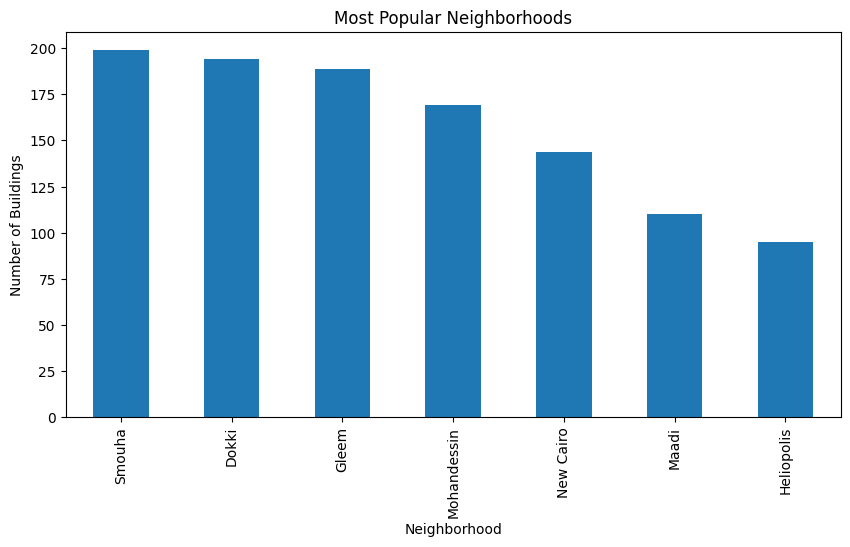

In [31]:
neighborhood_counts = df['Neighborhood'].value_counts()

neighborhood_counts.plot(kind='bar', figsize=(10, 5))


plt.title('Most Popular Neighborhoods')
plt.xlabel('Neighborhood')
plt.ylabel('Number of Buildings')
plt.show()


We chose bar chart as our most optimal choice of visualization to showcase the number of buildings in each category of Neighborhood

**Answer for Q1:** Most popular neighborhoods are Smouha, Dokki,and Gleem

**Q2:** Show the distribution of the energy consumption of each Building type.

Which type have the widest distribution of energy consumption?

Which (on average) has the highest consumption?.

**Visualization**

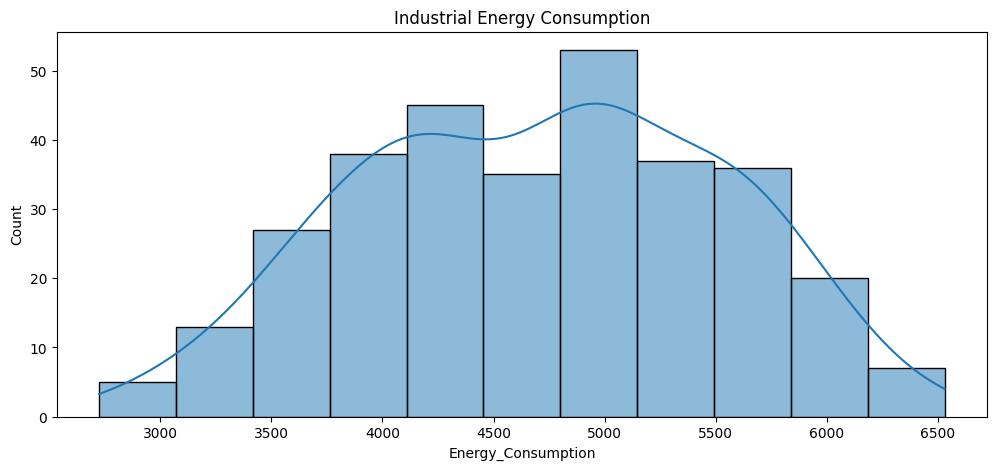

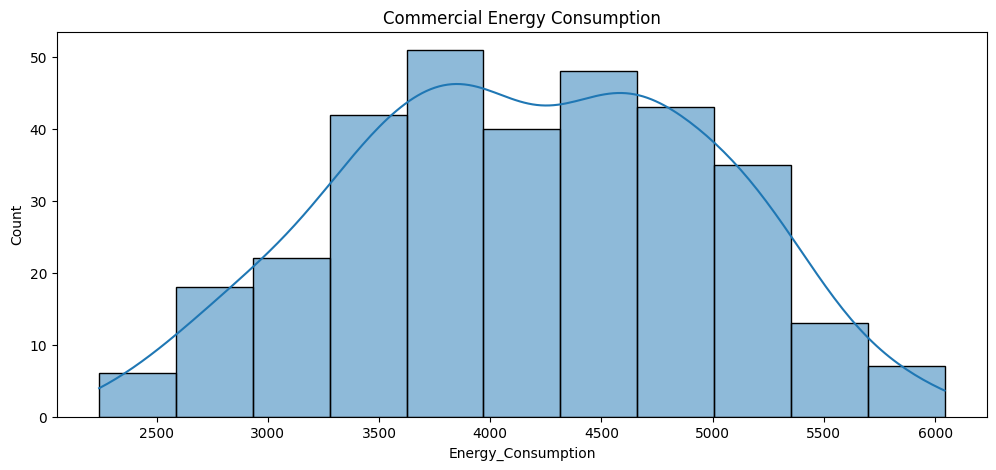

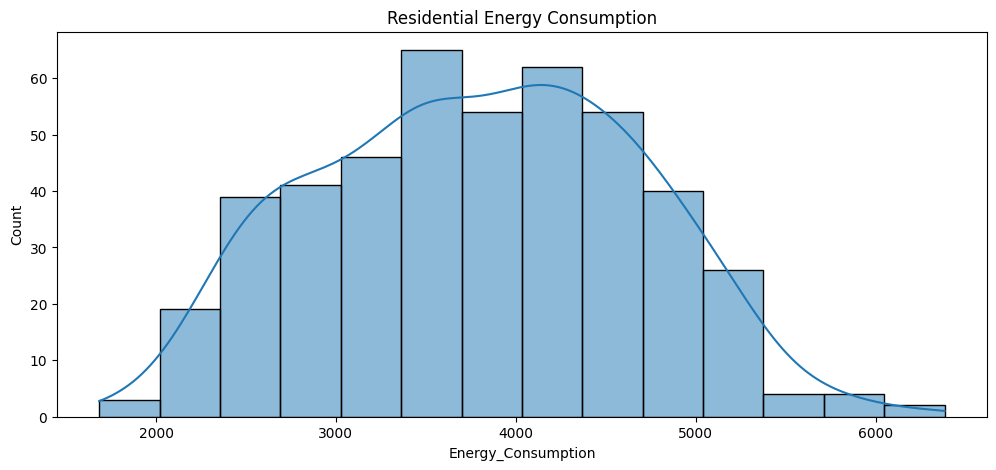

In [32]:
plt.figure(figsize=(12, 5))
sns.histplot(data=df[df['Building_Type'] == 'Industrial'],
             x='Energy_Consumption', kde=True)
plt.title('Industrial Energy Consumption')
plt.show()

plt.figure(figsize=(12, 5))
sns.histplot(data=df[df['Building_Type'] == 'Commercial'],
             x='Energy_Consumption', kde=True)
plt.title('Commercial Energy Consumption')
plt.show()

plt.figure(figsize=(12, 5))
sns.histplot(data=df[df['Building_Type'] == 'Residential'],
             x='Energy_Consumption', kde=True)
plt.title('Residential Energy Consumption')
plt.show()

We chose histograms as our most optimal choice to showcase the numerical distribution of the Energy_Consumption for each type of building to detect the highest distribution

In [33]:
df.groupby('Building_Type')['Energy_Consumption'].mean().sort_values(ascending=False)

Building_Type
Industrial     4708.418671
Commercial     4170.374462
Residential    3794.724183
Name: Energy_Consumption, dtype: float64

We wrote this code to determine the average highest consumption based on each type of building

Answer for Q2: Residential has the widest distribution and Industrial has the highest consumption.

**Q3:** How does the building size affect energy consumption?

**Visualization**

Text(0.5, 1.0, 'Scatter Plot of Building size vs Energy Consumption')

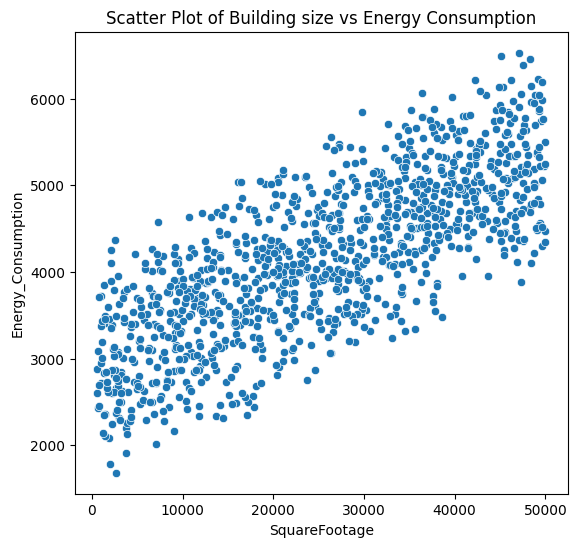

In [34]:
f = plt.figure(figsize=(14,6))
ax = f.add_subplot(121)
sns.scatterplot(x='SquareFootage', y='Energy_Consumption', data=df, ax=ax)
ax.set_title('Scatter Plot of Building size vs Energy Consumption')

We chose scatter plot as our most optimal visualization to showcase the relationship or correlation between the two variables (positive or negative or no correlation)

**Answer for Q3:** There exists a highly positive relationship between both varibales based on the visualization

**Q4:** Do buildings consume more energy if not maintained frequently?

**Visualization**

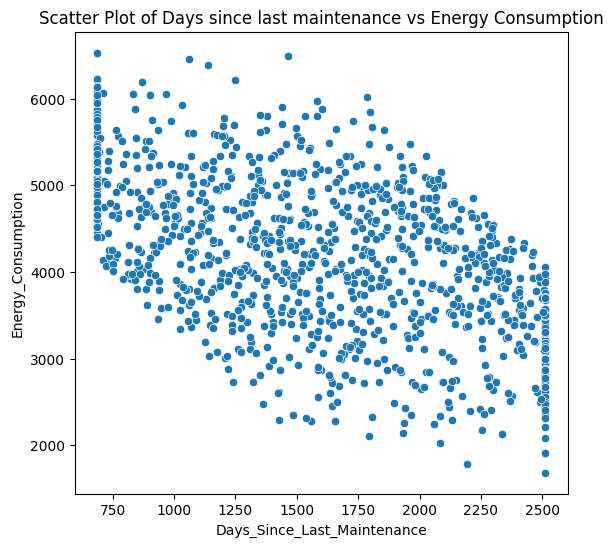

In [35]:
f = plt.figure(figsize=(14,6))
ax = f.add_subplot(122)
sns.scatterplot(x='Days_Since_Last_Maintenance', y='Energy_Consumption', data=df, ax=ax)
ax.set_title('Scatter Plot of Days since last maintenance vs Energy Consumption');

We chose scatter plot as our most optimal visualization to showcase the relationship or correlation between the two variables (positive or negative or no correlation)

**Answer for Q4:** Based on the visualization, it appears there is a negative relationship between both variables 

**Q5:** Are all the numerical variables normally distributed, or is there any skewness?

**Visualization**

In [36]:
df.dtypes

Building_ID                            object
Building_Type                          object
Governorate                            object
Neighborhood                           object
Day_of_Week                            object
Occupancy_Level                        object
Appliances_Usage_Level                 object
SquareFootage                           int64
Last_Maintenance_Date          datetime64[ns]
Average_Temperature                   float64
Energy_Consumption                    float64
Days_Since_Last_Maintenance             int64
Day_type                               object
dtype: object

We wrote this line to inspect the current data types of the columns in the dataset

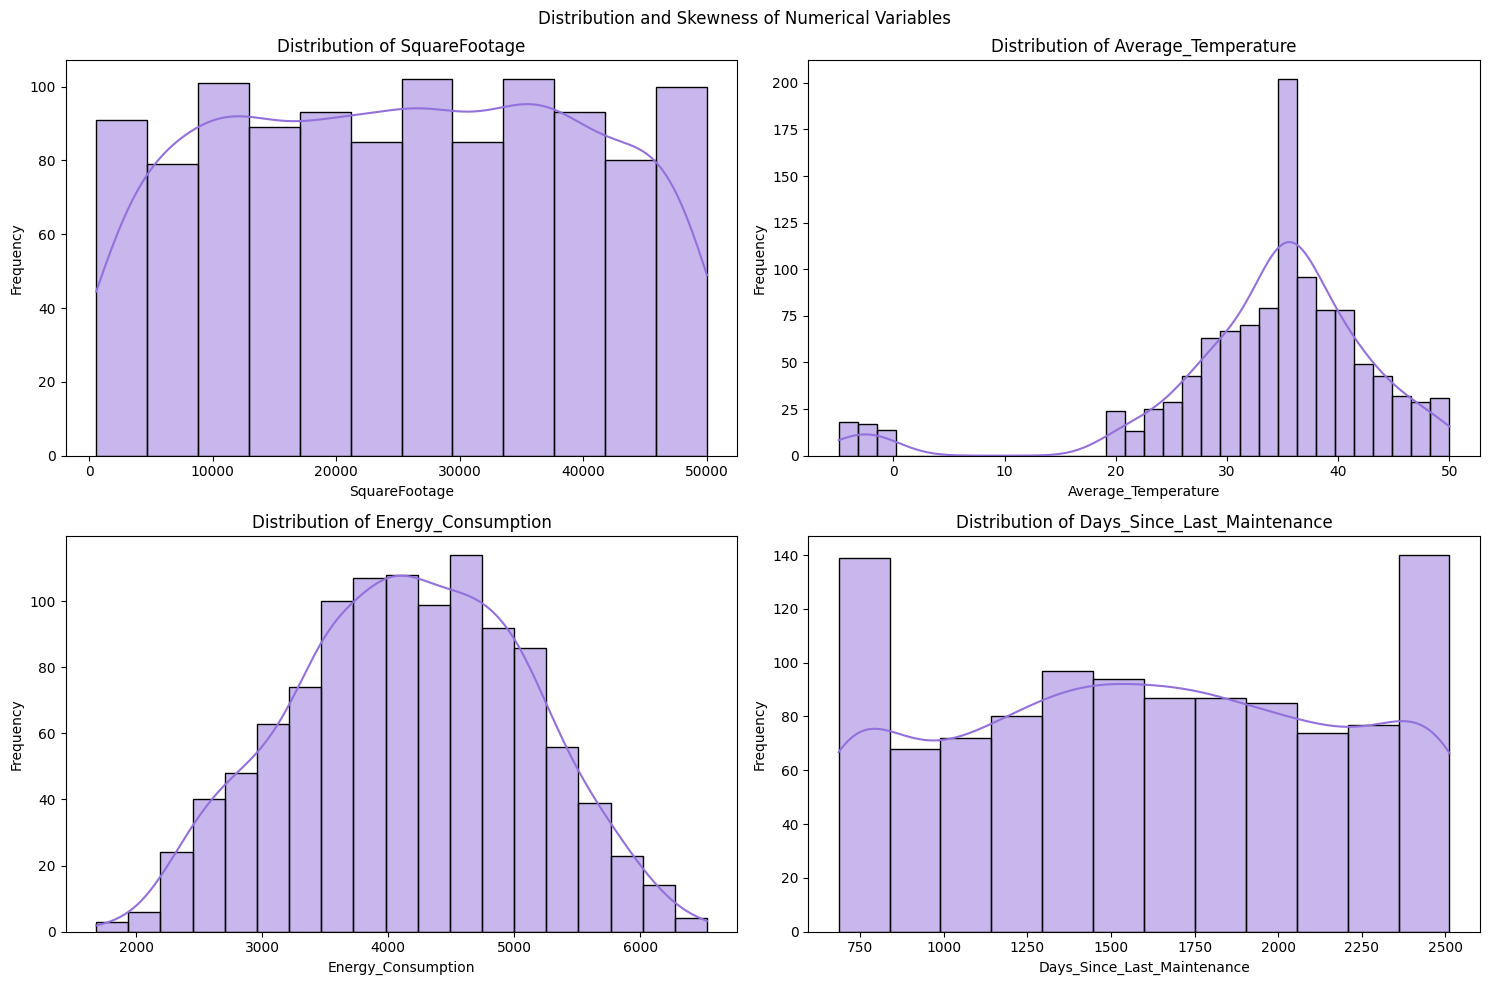

In [37]:
numerical_cols = [
    'SquareFootage',
    'Average_Temperature',
    'Energy_Consumption',
    'Days_Since_Last_Maintenance'
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for ax, col in zip(axes, numerical_cols):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        color='mediumpurple',
        ax=ax
    )

    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')

plt.suptitle(
    'Distribution and Skewness of Numerical Variables',
)

plt.tight_layout()
plt.show()


We chose histograms as our most optimal choice to showcase the numerical distribution of each numerical data to depict the type or distribution (normal, skewed, uniform) among each column

**Answer for Q5:** Only Energy_Consumption is normally distributed, while the other fields are uniformally distributed with some skewness and unusual values.

**Q6:** What is multicollinearity? And why is it a problem for linear regression? Does this problem exist in this
dataset?

**Visualization**

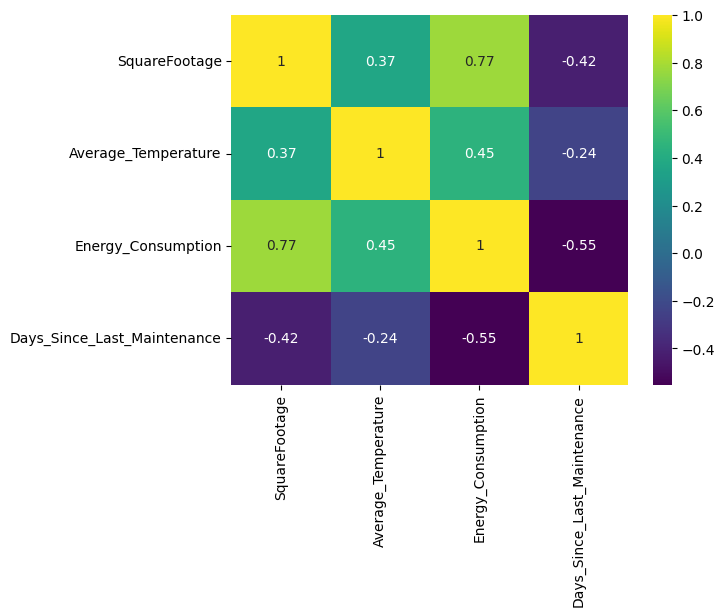

In [38]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr, cmap='viridis', annot = True);

We chose heatmap as our most optimal visualization to create a correlation matrix and depict the correlation between all variables and check for multicollinearity between independent variables.

**Answer for Q6:** multicollinearity is when the independent variables has high correlation between each other. This is a problem for Linear Regression mainly because it can create redundacy and noise for the model. Based on the correlation matrix, this problem does not exist as the independent varibles appear to have low to moderate correlation between each other. 

## Data Preparation for Modelling

_Apply any additional data preparation steps needed before modelling below. Show/output the changes to the dataset._

In [39]:
df = df.drop('Last_Maintenance_Date', axis = 1)

We dropped this column because we derived Days_Since_Last_Maintenance, so we no longer need it for our modelling

In [40]:
df.head()

,Building_ID,Building_Type,Governorate,Neighborhood,Day_of_Week,Occupancy_Level,Appliances_Usage_Level,SquareFootage,Average_Temperature,Energy_Consumption,Days_Since_Last_Maintenance,Day_type
0,BLD-1000-UD,Residential,Alexandria,Smouha,Wednesday,High,Low,7063,28.61,2713.95,2512,weekday
1,BLD-1001-AX,Commercial,Giza,Mohandessin,Tuesday,High,High,44372,35.26,5744.99,1727,weekday
2,BLD-1002-IH,Industrial,Cairo,New Cairo,Sunday,Medium,Low,19255,37.88,4101.24,2094,weekday
3,BLD-1003-HE,Residential,Alexandria,Dokki,Tuesday,Low,High,13265,35.06,3009.14,1206,weekday
4,BLD-1004-XD,Commercial,Alexandria,Smouha,Monday,Low,Low,13375,28.82,3279.17,1558,weekday


Changes after applying the method

In [41]:
categorical_columns = ['Building_Type', 'Governorate', 'Neighborhood','Day_of_Week', 'Day_type']
df_encode = pd.get_dummies(data=df,
                           columns=categorical_columns,
                           drop_first=True,
                           dtype='int8')

print('Columns in original data frame:\n',df.columns.values)
print('\nNumber of rows and columns in the dataset:',df.shape)
print('\nColumns in data frame after encoding dummy variable:\n',df_encode.columns.values)
print('\nNumber of rows and columns in the dataset:',df_encode.shape)

Columns in original data frame:
 ['Building_ID' 'Building_Type' 'Governorate' 'Neighborhood' 'Day_of_Week'
 'Occupancy_Level' 'Appliances_Usage_Level' 'SquareFootage'
 'Average_Temperature' 'Energy_Consumption' 'Days_Since_Last_Maintenance'
 'Day_type']

Number of rows and columns in the dataset: (1100, 12)

Columns in data frame after encoding dummy variable:
 ['Building_ID' 'Occupancy_Level' 'Appliances_Usage_Level' 'SquareFootage'
 'Average_Temperature' 'Energy_Consumption' 'Days_Since_Last_Maintenance'
 'Building_Type_Industrial' 'Building_Type_Residential'
 'Governorate_Cairo' 'Governorate_Giza' 'Neighborhood_Gleem'
 'Neighborhood_Heliopolis' 'Neighborhood_Maadi' 'Neighborhood_Mohandessin'
 'Neighborhood_New Cairo' 'Neighborhood_Smouha' 'Day_of_Week_Monday'
 'Day_of_Week_Saturday' 'Day_of_Week_Sunday' 'Day_of_Week_Thursday'
 'Day_of_Week_Tuesday' 'Day_of_Week_Wednesday' 'Day_type_weekend']

Number of rows and columns in the dataset: (1100, 24)


We did One Hot Encoding to the nominal values to prepare it for Linear Regression Modelling

In [42]:
df_encode.head()

,Building_ID,Occupancy_Level,Appliances_Usage_Level,SquareFootage,Average_Temperature,Energy_Consumption,Days_Since_Last_Maintenance,Building_Type_Industrial,Building_Type_Residential,Governorate_Cairo,...,Neighborhood_Mohandessin,Neighborhood_New Cairo,Neighborhood_Smouha,Day_of_Week_Monday,Day_of_Week_Saturday,Day_of_Week_Sunday,Day_of_Week_Thursday,Day_of_Week_Tuesday,Day_of_Week_Wednesday,Day_type_weekend
0,BLD-1000-UD,High,Low,7063,28.61,2713.95,2512,0,1,0,...,0,0,1,0,0,0,0,0,1,0
1,BLD-1001-AX,High,High,44372,35.26,5744.99,1727,0,0,0,...,1,0,0,0,0,0,0,1,0,0
2,BLD-1002-IH,Medium,Low,19255,37.88,4101.24,2094,1,0,1,...,0,1,0,0,0,1,0,0,0,0
3,BLD-1003-HE,Low,High,13265,35.06,3009.14,1206,0,1,0,...,0,0,0,0,0,0,0,1,0,0
4,BLD-1004-XD,Low,Low,13375,28.82,3279.17,1558,0,0,0,...,0,0,1,1,0,0,0,0,0,0


Changes after applying the method

In [43]:
occupancy_mapping = {
    'Low': 0,
    'Medium': 1,
    'High': 2
}

df_encode['Occupancy_Level'] = df_encode['Occupancy_Level'].map(occupancy_mapping)


Appliances_Usage_Level_mapping = {
    'Low': 0,
    'Medium': 1,
    'High': 2
}

df_encode['Appliances_Usage_Level'] = df_encode['Appliances_Usage_Level'].map(Appliances_Usage_Level_mapping)

We did Label Encoding for the ordinal columns to make it prepared for Linear Regression Modelling

In [44]:
df_encode.head()

,Building_ID,Occupancy_Level,Appliances_Usage_Level,SquareFootage,Average_Temperature,Energy_Consumption,Days_Since_Last_Maintenance,Building_Type_Industrial,Building_Type_Residential,Governorate_Cairo,...,Neighborhood_Mohandessin,Neighborhood_New Cairo,Neighborhood_Smouha,Day_of_Week_Monday,Day_of_Week_Saturday,Day_of_Week_Sunday,Day_of_Week_Thursday,Day_of_Week_Tuesday,Day_of_Week_Wednesday,Day_type_weekend
0,BLD-1000-UD,2,0,7063,28.61,2713.95,2512,0,1,0,...,0,0,1,0,0,0,0,0,1,0
1,BLD-1001-AX,2,2,44372,35.26,5744.99,1727,0,0,0,...,1,0,0,0,0,0,0,1,0,0
2,BLD-1002-IH,1,0,19255,37.88,4101.24,2094,1,0,1,...,0,1,0,0,0,1,0,0,0,0
3,BLD-1003-HE,0,2,13265,35.06,3009.14,1206,0,1,0,...,0,0,0,0,0,0,0,1,0,0
4,BLD-1004-XD,0,0,13375,28.82,3279.17,1558,0,0,0,...,0,0,1,1,0,0,0,0,0,0


Changes after applying the method

In [45]:
df_encode = df_encode.drop('Building_ID', axis = 1)

We dropped the Building_ID column as it is no longer meaningful to the modelling step.

## Modelling

_Apply the linear regression model below._

In [46]:
from sklearn.model_selection import train_test_split

x = df_encode.drop('Energy_Consumption',axis=1) 
y = df_encode['Energy_Consumption'] 

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=23)

print('Training dataset size:', x_train.shape[0])
print('Testing dataset size:', x_test.shape[0])

Training dataset size: 880
Testing dataset size: 220


We wrote this code to split our independent and dependent variable and split our datset into trining nd testing size

In [47]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()

lin_reg.fit(x_train, y_train);

We wrote this code to fit our dependent and independent variables in the train dataset into our Linear Regression Model

## Model Evaluation

Evaluate the model you applied.

In [48]:
y_pred = lin_reg.predict(x_test)


from sklearn.metrics import root_mean_squared_error
rmse=root_mean_squared_error(y_pred, y_test)

R_square = lin_reg.score(x_test,y_test)
print('The root mean square error (RMSE) is: ', rmse)
print('R^2 obtained is:', R_square)

The root mean square error (RMSE) is:  234.12885885066646
R^2 obtained is: 0.9384327977774756


We used R squared and root mean square error to evaluate the model's performnace

## Conclusion and Recommendations

Comment on the model performance and your findings from model evaluation. State the problems (if any) and suggest possible solutions. Would you recommend this model for an electrcity company aiming to estimate the energy levels of each building?

**Answer**: Based on the metrics used for the model evaluation, our model's performance is strong with accuracy score of 0.93. One of the problems faced is that there was outliers in the distribution of the numerical data. We would recommend this model based on its strong performance; however, the company should take into consideration that the model's prediction is not 100% accurate and is based on estimates.

## Bonus (Outlier Detection and Removal)
We're going to detect and remove outliers to enhance our model's performance

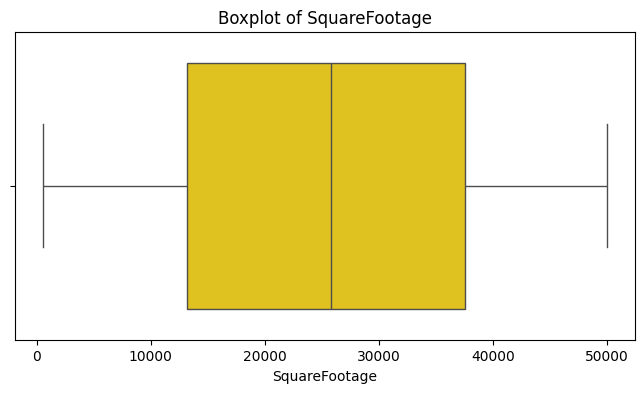

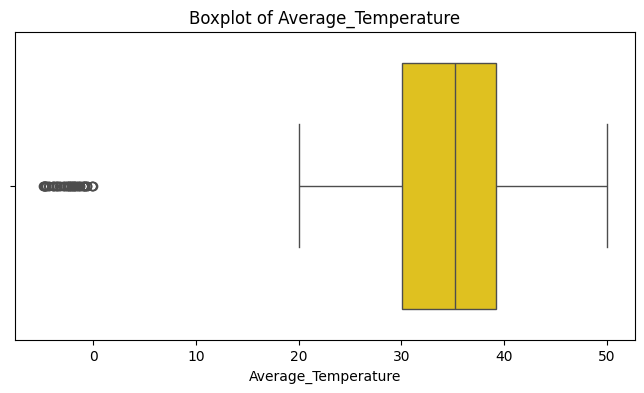

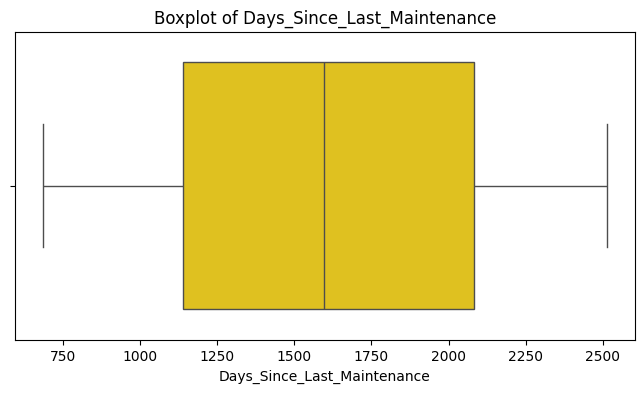

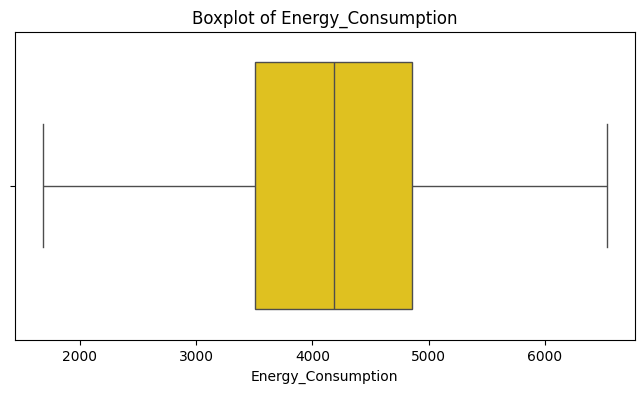

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt

numerical_cols = [
    'SquareFootage',
    'Average_Temperature',
    'Days_Since_Last_Maintenance',
    'Energy_Consumption'
]

for col in numerical_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col], color='gold')
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.show()

We used the boxplot in order to detect the outliers in each numerical column and it appears that average temperature has several outliers.

In [50]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df_encode.drop(columns=['Energy_Consumption', 'Building_ID'],
                   errors='ignore')
y = df_encode['Energy_Consumption']

# Split the data
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

We wrote this code to split the data into training and testing to use the training dataset into removing the outliers in Average_Temprature.

In [51]:
Q1 = x_train['Average_Temperature'].quantile(0.25)
Q3 = x_train['Average_Temperature'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Included_rows = (
    (x_train['Average_Temperature'] >= lower_bound) &
    (x_train['Average_Temperature'] <= upper_bound)
)

x_train_clean = x_train.loc[Included_rows].copy()
y_train_clean = y_train.loc[Included_rows].copy()

print("Training rows before:", len(x_train))
print("Training rows after:", len(x_train_clean))

Lower bound: 15.612500000000006
Upper bound: 53.11249999999999
Training rows before: 880
Training rows after: 841


We wrote this code to calculate the upper and lower bounds using quantile function and interquartile, then we located the included rows free of outliers only in our cleaned dataset using the copy method.

In [52]:
lin_reg = LinearRegression()

lin_reg.fit(x_train, y_train);

We wrote this code to train the model on the train dataset free of the outliers

In [53]:
from sklearn.metrics import root_mean_squared_error, r2_score
y_pred = lin_reg.predict(x_test)

rmse = root_mean_squared_error(y_test, y_pred)
R_square = r2_score(y_test, y_pred)

print("Test RMSE:", rmse)
print("Test R²:", R_square)

Test RMSE: 217.24849718694176
Test R²: 0.9445140551426139


We used evaluation metrics including the root mean squared error and R squared to determine the accuracy after removing the outliers and the model appears to be performing better with a little higher accuracy score after outliers removal.

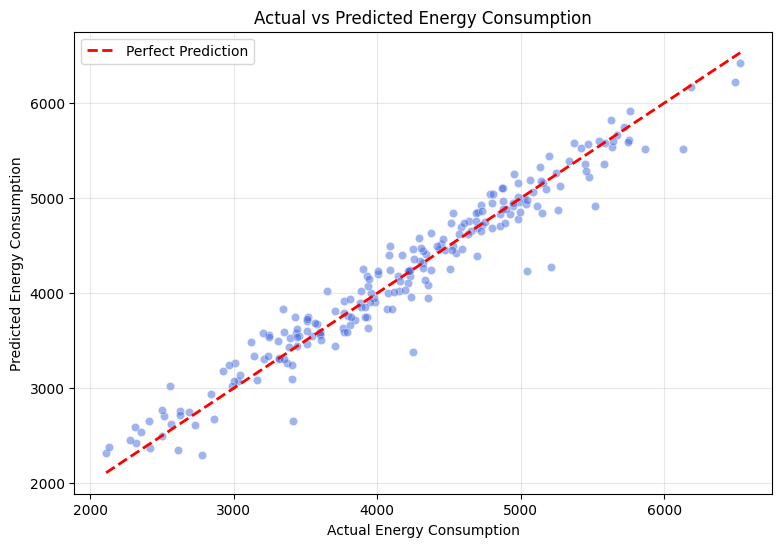

In [54]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.5,
    color='royalblue'
)

# Perfect prediction reference line
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='red',
    linestyle='--',
    linewidth=2,
    label='Perfect Prediction'
)

plt.title('Actual vs Predicted Energy Consumption')
plt.xlabel('Actual Energy Consumption')
plt.ylabel('Predicted Energy Consumption')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## External Sources used in the notebook for unknown methods
**Used for Dataset inspection:** https://coderivers.org/blog/dataset-in-python/

**Used for column data type conversion:** https://talkcodetome.com/python/data%20science/data%20cleaning/data%20preprocessing/how-to-fix-incorrect-column-data-types-when-importing-data-into-python/

**Used for date feature engineering:** https://deffro.github.io/tutorials/feature-engineering-with-dates/

**Used for target column trimming text and type conversion:** https://pandas.pydata.org/docs/reference/api/pandas.to_numeric.html

**Used to get number of days from last maintenance day till today:** https://pandas.pydata.org/docs/user_guide/timeseries.html
https://pandas.pydata.org/docs/reference/api/pandas.Timestamp.normalize.html
https://pandas.pydata.org/pandas-docs/version/1.5/reference/api/pandas.Timestamp.today.html
https://pandas.pydata.org/docs/reference/api/pandas.Timedelta.days.html

**Used to fill new columns based on certain conditions:** https://pandas.pydata.org/docs/user_guide/indexing.html

**Used for first question in Data exploration:**
https://www.geeksforgeeks.org/pandas/bar-plot-in-matplotlib/

**Used for fifth question in Data exploration:** https://seaborn.pydata.org/generated/seaborn.kdeplot.html
https://seaborn.pydata.org/generated/seaborn.histplot.html

**Used for Label Encoding of the ordinal variables:** https://www.geeksforgeeks.org/machine-learning/ml-label-encoding-of-datasets-in-python/

**Used for outlier detection and removal:** https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html
https://numpy.org/doc/stable/reference/generated/numpy.quantile.html 

**Rest of the code is either derived from tutorial labs or written by us.**